# 13 · Agent reliability and experimental design

**Question.** Does adaptive tool use improve outcomes enough to justify its additional complexity?

[Download the executed notebook](https://chikuang.github.io/teaching/genai/notebooks/13-agent-reliability.ipynb)

A successful demonstration does not measure reliability. We need repeated tasks, failures with known causes, and a comparison that accounts for additional calls. This chapter constructs a controlled simulator: a cached answer, a one-pass tool workflow, and a bounded retry policy solve the same mean-estimation requests. These are programmed policies, not measured LLM agents. Their role is to teach experimental design before introducing an expensive or opaque policy.

**Prerequisites:** Chapters 11–12. **Outcomes:** distinguish trajectories from tasks; classify failure modes; inject reproducible failures; compare paired outcomes with clustered uncertainty; measure the cost of recovery.

## Pipeline and framework

![Run paired policies on the same held-out tasks and repeated failure scenarios, log full trajectories, aggregate by task, bootstrap task clusters and inspect ablations. Remember: pair the tasks; resample task clusters, not individual calls.](https://chikuang.github.io/teaching/genai/_static/diagrams/13-reliability.png)

An agent evaluation needs a **task-level experimental design** and a **trajectory-level trace**. The trace explains a result; the task is often the unit used for population-level uncertainty. A retry can create more calls without creating more independent tasks.

| Stage | Artifact | Why it is needed |
|:--|:--|:--|
| Specify tasks and failures | Task IDs, repetitions, and a reproducible failure process | Different policies face comparable difficulty. |
| Execute paired policies | One trace per policy, task, and repetition | Compare like with like and retain errors and stop reasons. |
| Aggregate and resample | Task-level paired differences | Keep within-task dependence when estimating uncertainty. |
| Diagnose interventions | Success, cost, failure labels, and ablation contrasts | Find whether gains came from retries, memory, or another component. |

In this chapter the tool outcomes and policies are programmed experiments. They demonstrate how to measure reliability, not a measured claim about an external LLM. When moving to a stochastic model, add model/version and decoding settings to the trace and repeat generations under the same task design. If tasks share a source document or user, consider that larger cluster when defining the sampling unit.

## 13.1 · Define success and record the whole trajectory

A task requests the mean of a current dataset. Success requires a numeric answer within a fixed tolerance of the true current mean. A cached answer may be stale. A tool can time out or return malformed data. Abstention, incorrect answers, invalid tool payloads, and exhaustion of the call budget are different outcomes and remain separate in the log.

For task $i$ and replicate $r$, let $S_{ir}$ be success and $C_{ir}$ the number of tool calls. We report mean success, mean calls, and a declared utility $S_{ir}-\lambda C_{ir}$. The value of $\lambda$ is a decision preference, not a quantity the experiment magically identifies.

## 13.2 · Construct tasks and repeatable tool failures

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

rng = np.random.default_rng(13)
n_tasks, repeats = 80, 5
old_data = rng.normal(size=(n_tasks, 20))
changed = rng.random(n_tasks) < 0.4
current_data = old_data + changed[:, None]*0.5
cached_means = old_data.mean(1)
truth = current_data.mean(1)
failure_probability = rng.uniform(0.1, 0.45, size=n_tasks)

def lookup(task, replicate, attempt):
    # Same task/replicate/attempt produces the same observation for every policy.
    local = np.random.default_rng(130000 + 1000*task + 10*replicate + attempt)
    u = local.random()
    if u < 0.03:
        return {'status': 'malformed', 'values': ['not a number']}
    if u < 0.03 + failure_probability[task]:
        return {'status': 'timeout'}
    return {'status': 'ok', 'values': current_data[task].tolist()}

print('Tasks with stale cached answers:', int(changed.sum()))
print('Range of timeout probabilities:', failure_probability.min().round(2),
      failure_probability.max().round(2))

Tasks with stale cached answers: 31
Range of timeout probabilities: 0.11 0.45


Common random streams make a policy's first call encounter the same failure as another policy's first call. Later attempts have their own observations. This creates a paired experiment rather than confounding the comparison with unrelated random failures. All failure rates and stale-data shifts are chosen for illustration.

## 13.3 · Compare policy interventions

The retry policy retries timeouts up to a call budget. It stops on a malformed payload because a data-contract violation is not assumed transient. The optional cache fallback is an explicit ablation: it may answer more often while using stale information.

In [2]:
def run_policy(task, replicate, budget, use_cache=False):
    trace = []
    for attempt in range(budget):
        observation = lookup(task, replicate, attempt)
        trace.append(observation['status'])
        if observation['status'] == 'ok':
            value = float(np.mean(observation['values']))
            return {'value': value, 'status': 'answered', 'calls': len(trace), 'trace': trace}
        if observation['status'] == 'malformed':
            return {'value': None, 'status': 'invalid_payload', 'calls': len(trace), 'trace': trace}
    if use_cache:
        return {'value': float(cached_means[task]), 'status': 'cached',
                'calls': len(trace), 'trace': trace}
    return {'value': None, 'status': 'budget_exhausted', 'calls': len(trace), 'trace': trace}

configurations = {'Cache only': (0, True), 'One pass': (1, False),
                  'Retry up to 3': (3, False), 'Retry plus cache': (3, True)}
results = {}
for name, (budget, fallback) in configurations.items():
    rows = []
    for task in range(n_tasks):
        for replicate in range(repeats):
            result = run_policy(task, replicate, budget, fallback)
            result.update(task=task, replicate=replicate)
            result['success'] = (result['value'] is not None
                                 and abs(result['value']-truth[task]) < 1e-8)
            rows.append(result)
    results[name] = rows
    print(name, 'success', round(np.mean([r['success'] for r in rows]), 3),
          'calls', round(np.mean([r['calls'] for r in rows]), 3),
          'outcomes', dict(Counter(r['status'] for r in rows)))

Cache only success 0.612 calls 0.0 outcomes {'cached': 400}
One pass success 0.692 calls 1.0 outcomes {'answered': 277, 'budget_exhausted': 111, 'invalid_payload': 12}
Retry up to 3 success 0.93 calls 1.39 outcomes {'answered': 372, 'budget_exhausted': 14, 'invalid_payload': 14}
Retry plus cache success 0.952 calls 1.39 outcomes {'answered': 372, 'cached': 14, 'invalid_payload': 14}


This comparison does not show that a language model is needed. The adaptive behavior is a short programmed policy. It tests the benefit of retries and the risk of stale fallback under specified failure mechanisms. An actual LLM comparison would replace the policy while retaining the task set, dispatcher, scoring rule, and trace accounting.

## 13.4 · Resample tasks, keeping repetitions together

Five repetitions of one task share its data, truth, and failure rate. Resampling all 400 trajectories independently would ignore that clustering. We first average the paired success difference within each task and then bootstrap task means.

Retry minus one-pass success: 0.238
Task-cluster bootstrap interval: [0.195 0.28 ]


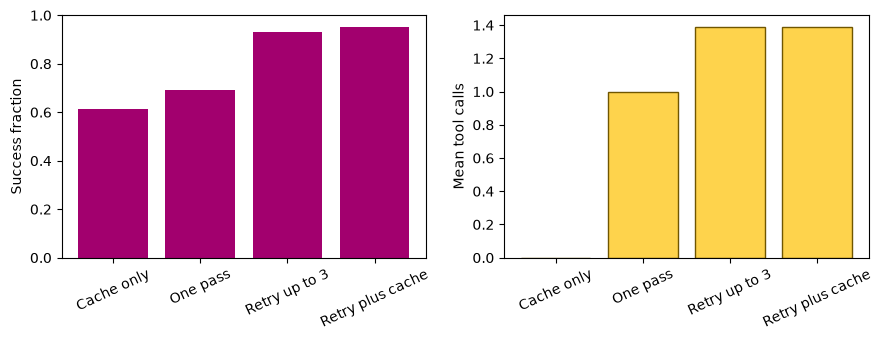

In [3]:
def success_matrix(name):
    return np.array([r['success'] for r in results[name]], dtype=float).reshape(n_tasks, repeats)

paired_by_task = (success_matrix('Retry up to 3')-success_matrix('One pass')).mean(1)
ids = rng.integers(n_tasks, size=(3000, n_tasks))
bootstrap = paired_by_task[ids].mean(1)
print('Retry minus one-pass success:', round(paired_by_task.mean(), 3))
print('Task-cluster bootstrap interval:', np.quantile(bootstrap, [0.025, 0.975]).round(3))

names = list(configurations)
success = [np.mean([r['success'] for r in results[name]]) for name in names]
calls = [np.mean([r['calls'] for r in results[name]]) for name in names]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
axes[0].bar(names, success, color='#a2006e')
axes[1].bar(names, calls, color='#fed34c', edgecolor='#705600')
axes[0].set(ylabel='Success fraction', ylim=(0, 1))
axes[1].set(ylabel='Mean tool calls')
for ax in axes:
    ax.tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.show()

The interval describes the chosen simulator and sampled task distribution. It does not include uncertainty about whether that simulator resembles production. When tasks are sampled by document or user, move the resampling unit to that higher level.

## 13.5 · Inspect cost and failure examples

In [4]:
cost_per_call = 0.03
for name, rows in results.items():
    utility = np.mean([float(r['success'])-cost_per_call*r['calls'] for r in rows])
    answered = [r for r in rows if r['value'] is not None]
    wrong_answer_rate = np.mean([not r['success'] for r in answered]) if answered else np.nan
    print(name, 'utility', round(utility, 3),
          'error among answered', round(wrong_answer_rate, 3))

example = next(r for r in results['Retry up to 3'] if len(r['trace']) > 1)
print('Recovery trace:', example)

Cache only utility 0.612 error among answered 0.388
One pass utility 0.662 error among answered 0.0
Retry up to 3 utility 0.888 error among answered 0.0
Retry plus cache utility 0.911 error among answered 0.013
Recovery trace: {'value': 0.8543511034891461, 'status': 'answered', 'calls': 2, 'trace': ['timeout', 'ok'], 'task': 1, 'replicate': 2, 'success': np.True_}


These costs are illustrative units per call, not measured currency or wall-clock latency. A deployed experiment should log actual tokens, service charges, elapsed time, retries, and model/tool versions. Do not erase failed trajectories before calculating cost.

A useful failure taxonomy distinguishes task interpretation, invalid action proposals, tool availability, invalid returned data, incorrect calculation, unsupported final answer, and budget exhaustion. A timeout followed by successful recovery is a successful trajectory with an observed intermediate failure, not a run that “never failed.”

## 13.6 · Factorial comparisons and adaptive evaluation

To test memory, vary only the memory feature while holding the other components fixed. To test retries, hold the policy and tool contracts fixed while changing the retry rule. For two factors, evaluate all four combinations and inspect interactions: memory could help after a retrieval failure while harmfully overriding fresh evidence when retrieval succeeds.

Do not repeatedly inspect test outcomes, change the policy, and continue calling the same set “held out.” Use a development suite for repairs and a locked evaluation suite for final reporting. Record the number of policy variants considered, since selection among many noisy estimates creates optimism.

Prompt injection tests should include untrusted documents and tool messages that request unauthorized behavior. Score whether the execution boundary rejects invalid actions, not merely whether the final response sounds cautious. The harmless adversarial-note experiment in Chapter 12 is one deterministic unit test, not a comprehensive security evaluation.

## 13.7 · Exercises and worked solutions

1. **Retry probability:** if independent attempts fail with a fixed probability $p$, what is success by three attempts? **Solution:** $1-p^3$. With task-specific failure rates, average $1-p_i^3$ across tasks; substituting the average failure rate generally gives a different result.
2. **Persistent failure:** why can retries fail to help? **Solution:** an invalid credential, missing dataset, or malformed contract can persist across attempts. The independent transient-failure model then does not apply.
3. **Experimental unit:** why bootstrap 80 tasks rather than 400 trajectories? **Solution:** repeated trajectories share task characteristics. Task resampling retains that dependence and targets variation across the sampled task population.
4. **Cache fallback:** can answering more questions reduce reliability? **Solution:** yes. A stale cache may convert honest abstentions into incorrect answers. Report coverage and error among answered cases together.
5. **Budget fairness:** are two policies equivalent because both have a three-call ceiling? **Solution:** no. Their actual call distributions can differ. Report both the permitted budget and realized costs, and compare utility under a declared cost model.
6. **Multiple agents:** what baseline should precede adding more agents? **Solution:** a strong single-policy workflow with the same evidence and comparable total budget. Multiple samples, added tools, or extra tokens can explain gains without any benefit from agent-to-agent communication.

## 13.8 · Transition to a complete project

Use the evaluation principles from [Chapter 11](https://chikuang.github.io/teaching/genai/chapters/11-evaluation-uncertainty.html) with the execution boundary from [Chapter 12](https://chikuang.github.io/teaching/genai/chapters/12-agents.html). [Chapter 14](https://chikuang.github.io/teaching/genai/chapters/14-capstone.html) combines these ideas into a fully runnable statistical simulation assistant and a reproducible project report.